# MNIST labels (number, MorphoMNIST, RT_MNIST)

In [20]:
%load_ext autoreload
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import libraries.morphomnist.measure as m

# Personnal
from libraries.data_loader import load_datas

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Classical label

In [21]:
path = r"datas/brut/mnist.npz"
keys = ['x_train', 'y_train', 'x_test', 'y_test']

X_TRAIN, Y_TRAIN, X_VAL, Y_VAL = load_datas(path, keys)


X_TRAIN = X_TRAIN.reshape((60000, 1, 28, 28))
X_VAL = X_VAL[:].reshape((10000, 1, 28, 28))


X_TRAIN.shape, X_VAL.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

# 1. Get and Save MorphoMNIST labels

In [3]:
colnames = ['area', 'thickness', 'slant', 'width', 'height']

In [5]:
%autoreload 2
img = X_train[:, 0].copy()

def fct(img) :
    return pd.Series(np.array(m.measure_image(img, threshold = 0.35, scale=8, verbose = 0)))

## 1.1. Train MorphoMNIST 

In [ ]:
batchsize = 1000
batch_range_train = range(0, X_train[:].shape[0] +1, batchsize)

MorphoMNIST = []
for i, batch in enumerate(batch_range_train[:-1]) :
    print(f"Epoch {i+1}/{len(batch_range_train) -1}")
    MorphoMNIST.append(pd.DataFrame(map(fct, X_train[batch:batch_range_train[i +1], 0])))

MorphoMNIST = pd.concat(MorphoMNIST)
MorphoMNIST.columns = colnames
MorphoMNIST["number"] = Y_train
MorphoMNIST

In [11]:
MorphoMNIST

,area,thickness,slant,width,height,large,number
0,107.1875,2.525400,0.231577,14.523651,19.889152,23.50,5
1,123.0625,2.570187,0.330892,15.385168,19.359169,21.00,0
2,78.1875,1.853382,-0.213113,20.472912,19.133937,24.50,4
3,67.3750,2.922822,0.507930,5.406406,19.768806,16.25,1
4,91.0000,2.244745,0.008993,13.273560,19.492584,19.00,9
...,...,...,...,...,...,...,...
995,101.9375,1.918180,0.365282,11.815953,19.969981,20.25,8
996,108.3125,2.509289,0.363884,13.319370,19.699682,21.25,3
997,86.4375,2.031193,0.259695,14.089260,20.130904,23.75,5
998,82.0000,1.667213,0.310604,15.224760,19.723788,21.00,6


In [12]:
MorphoMNIST_path = r"datas\MorphoMNIST_Train.csv"
MorphoMNIST_path

'datas\\MorphoMNIST_Train.csv'

In [15]:
# MorphoMNIST.to_csv(MorphoMNIST_path, index=False)
MorphoMNIST = pd.read_csv(MorphoMNIST_path, index_col = None)
MorphoMNIST

,area,thickness,slant,width,height,large,number
0,107.1875,2.525400,0.231577,14.523651,19.889152,23.50,5
1,123.0625,2.570187,0.330892,15.385168,19.359169,21.00,0
2,78.1875,1.853382,-0.213113,20.472912,19.133937,24.50,4
3,67.3750,2.922822,0.507930,5.406406,19.768806,16.25,1
4,91.0000,2.244745,0.008993,13.273560,19.492584,19.00,9
...,...,...,...,...,...,...,...
59995,101.9375,1.918180,0.365282,11.815953,19.969981,20.25,8
59996,108.3125,2.509289,0.363884,13.319370,19.699682,21.25,3
59997,86.4375,2.031193,0.259695,14.089260,20.130904,23.75,5
59998,82.0000,1.667213,0.310604,15.224760,19.723788,21.00,6


## 1.2. Validation MorphoMNIST

In [67]:
colnames = ['area', 'thickness', 'slant', 'width', 'height']
def get_measures(img) :
    return pd.Series(np.array(m.measure_image(img, threshold = 0.5, scale=4, verbose = 0))) # precision  threshold = 0.35, scale=10,

In [68]:
batchsize = 10
batch_range_val = range(0, X_VAL[:].shape[0] +1, batchsize)

MorphoMNIST_val = []
for i, batch in enumerate(batch_range_val[:2]) :
    print(f"Epoch {i+1}/{len(batch_range_val) -1}")
    MorphoMNIST_val.append(pd.DataFrame(map(get_measures, X_VAL[batch:batch_range_val[i +1], 0])))

MorphoMNIST_val = pd.concat(MorphoMNIST_val)

Epoch 1/1000
Epoch 2/1000


In [69]:
MorphoMNIST_val.head(10)

,0,1,2,3,4
0,71.1250,2.143606,0.070331,15.107538,19.608231
1,112.8125,2.567078,-0.173172,17.612352,19.888424
2,39.1250,1.824994,0.291111,3.708323,19.742677
3,146.9375,3.486693,0.072260,14.727768,19.037417
4,75.1250,1.955419,-0.127713,14.955419,18.808067
5,53.8125,2.508361,0.295906,4.473295,19.272877
6,83.0625,2.083651,-0.087171,16.728221,19.057381
7,83.1250,2.400471,-0.514808,10.926269,18.839604
8,121.1250,3.157191,0.264532,17.265899,18.469700
9,125.2500,2.781327,0.291419,15.199156,18.984024


In [62]:
MM_test

,area,thickness,slant,width,height,number
0,71.1250,2.143606,0.070331,15.107538,19.608231,7
1,112.8125,2.567078,-0.173172,17.612352,19.888424,2
2,39.1250,1.824994,0.291111,3.708323,19.742677,1
3,146.9375,3.486693,0.072260,14.727768,19.037417,0
4,75.1250,1.955419,-0.127713,14.955419,18.808067,4
...,...,...,...,...,...,...
9995,152.6250,3.825798,-0.025117,16.042018,19.413860,2
9996,134.4375,3.497868,-0.074435,14.627779,19.507176,3
9997,114.4375,3.243076,0.197113,11.686910,19.369146,4
9998,103.7500,2.803574,0.528292,15.144704,14.670115,5


In [35]:
MorphoMNIST_val.columns = colnames
MorphoMNIST_val["number"] = Y_VAL
MorphoMNIST_val

,area,thickness,slant,width,height,number
0,85.97,2.461217,0.070453,15.059736,19.595802,7
1,132.22,3.028321,-0.173207,17.604736,19.876568,2
2,47.89,2.305435,0.291115,3.681872,19.723181,1
3,163.94,3.741352,0.072139,14.697578,19.029715,0
4,92.36,2.369963,-0.127699,14.933991,18.804047,4
...,...,...,...,...,...,...
95,169.81,4.210886,-0.025216,16.083076,19.398017,2
96,151.04,4.144205,-0.074492,14.592929,19.492500,3
97,129.14,3.794109,0.197116,11.676078,19.358941,4
98,120.49,3.095612,0.528343,15.135877,14.665711,5


In [42]:
MM_recent = MorphoMNIST_val.copy()
MM_recent.index = np.arange(10000)
MM_recent.to_csv(r"datas\MorphoMNIST\MorphoMNIST_Test_2.csv")

In [61]:
MM_test = pd.read_csv(r"datas\MorphoMNIST\MorphoMNIST_Test.csv")

In [ ]:
diff = MM_test -MM_recent

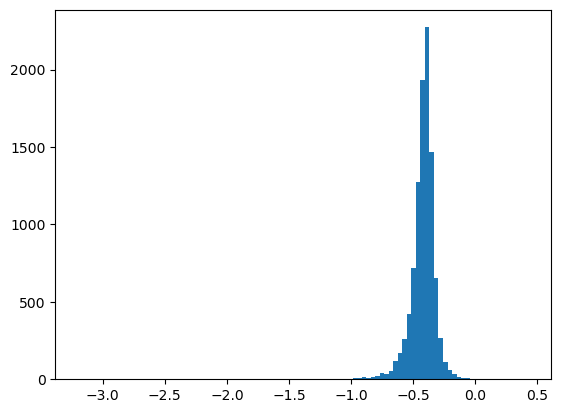

In [60]:
plt.hist(diff["thickness"], bins = 100)
plt.show()

In [26]:
MorphoMNIST_val_path = r"datas\MorphoMNIST\MorphoMNIST_Test.csv"
MorphoMNIST_val_path

'datas\\MorphoMNIST\\MorphoMNIST_Test.csv'

In [30]:
MorphoMNIST_val.to_csv(MorphoMNIST_val_path, index=False)

In [ ]:
import scipy as sc
from scipy.stats import gaussian_kde

In [ ]:
# path = r"../IMG"

w, h = len(MorphoMNIST_val.columns)//2 , 2
s = 3.5
fig = plt.figure(figsize = (s*w, s*h))

for i, col in enumerate(list(MorphoMNIST_val.columns[:-1])) :
    Y = MorphoMNIST_val[col]
    kde_y = gaussian_kde(Y)
    
    grid = np.linspace(Y.min(), Y.max(), 100) 
    p_Y = kde_y(grid)

    plt.subplot(h, w, i+1)
    plt.title(col.upper())
    plt.plot(grid, p_Y, linewidth = 2)
    plt.fill_between(
        x= grid, 
        y1= p_Y, 
        color= "b",
        alpha= 0.2)

    # plt.ylim(0, 1.0)
    # plt.grid(axis = "y")

fig.text(0.5, -0.1, 'Densities', ha='center', fontsize = 14)
fig.text(0.08, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)
# fig.savefig(os.path.join(path, "Morpho-MNIST - Density.pdf"), bbox_inches = 'tight')

In [2]:
import numpy as np
import pandas as pd

In [9]:
df = pd.DataFrame(np.array([np.arange(10),  np.random.randint(0, 10, 10)]).T)
df

,0,1
0,0,9
1,1,0
2,2,7
3,3,5
4,4,5
5,5,8
6,6,9
7,7,7
8,8,1
9,9,9


In [10]:
%load_ext rpy2.ipython

In [ ]:
%%R -i df -w 5 -h 5 --units in -r 200
install.packages("ggplot2", repos = "http://cran.us.r-project.org", quiet = TRUE)
library(ggplot2)
ggplot(df)

In [16]:
110*166 /8

2282.5